In [16]:
import pandas as pd

In [23]:
data = {
        'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain', 'Rain', 'Overcast', 'Sunny', 'Sunny', 'Rain', 'Sunny', 'Overcast', 'Overcast', 'Overcast'],
        'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool', 'Cool', 'Cool', 'Mild', 'Cool', 'Mild', 'Mild', 'Mild', 'Cool', 'Mild'],
        'Humidity': ['High', 'High', 'High', 'High', 'Normal', 'Normal', 'Normal', 'High', 'Normal', 'Normal', 'Normal', 'High', 'High', 'Normal'],
        'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 'Weak', 'Weak'],
        'Play Tennis': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'No']
       }

In [24]:
df = pd.DataFrame(data)

In [25]:
df

,Outlook,Temperature,Humidity,Wind,Play Tennis
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


#### Draw a contingency table
It is usually drawn when we want to find the relationship between two categorical variables

In [26]:
contingency_table = pd.crosstab(df['Outlook'], df['Play Tennis'])

In [27]:
contingency_table

Play Tennis,No,Yes
Outlook,,
Overcast,1,4
Rain,1,3
Sunny,3,2


##### For displaying the margin totals

In [30]:
c_margins = pd.crosstab(df['Outlook'], df['Play Tennis'], margins=True)

In [31]:
c_margins

Play Tennis,No,Yes,All
Outlook,,,
Overcast,1,4,5
Rain,1,3,4
Sunny,3,2,5
All,5,9,14


#### Probability Analysis using Contingency Tables

Ques. Calculate the joint probabilities.

In [32]:
joint_prob = pd.crosstab(df['Outlook'], df['Play Tennis'], normalize=True)

In [33]:
joint_prob

Play Tennis,No,Yes
Outlook,,
Overcast,0.071429,0.285714
Rain,0.071429,0.214286
Sunny,0.214286,0.142857


Ques. Calculate marginal probabilities.

In [34]:
margin_prob = pd.crosstab(df['Outlook'], df['Play Tennis'], normalize=True, margins=True)

In [35]:
margin_prob

Play Tennis,No,Yes,All
Outlook,,,
Overcast,0.071429,0.285714,0.357143
Rain,0.071429,0.214286,0.285714
Sunny,0.214286,0.142857,0.357143
All,0.357143,0.642857,1.000000


In [64]:
# 0.071429 + 0.285714 + 0.071429 + 0.214286 + 0.214286 + 0.142857

#### Conditional Probability

Ques. Calculate the conditional probability for Outlook and Play Tennis.<br>
Prob(Outlook = Rainy | Play Tennis)

In [45]:
c_table = pd.crosstab(df['Outlook'], df['Play Tennis'], margins=True).reset_index()
c_table

Play Tennis,Outlook,No,Yes,All
0,Overcast,1,4,5
1,Rain,1,3,4
2,Sunny,3,2,5
3,All,5,9,14


In [52]:
prob_play_tennis = c_table.loc[3,'Yes']/c_table.loc[3,'All']
prob_play_tennis

0.6428571428571429

In [55]:
prob_of_rain = c_table.loc[1,'All']/c_table.loc[3,'All']
prob_of_rain

0.2857142857142857

In [57]:
prob_rain_and_play = prob_play_tennis * prob_of_rain
prob_rain_and_play

0.1836734693877551

In [58]:
prob_rain_given_tennis = prob_rain_and_play/prob_play_tennis
prob_rain_given_tennis

0.2857142857142857

#### Visualization of Outlook

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

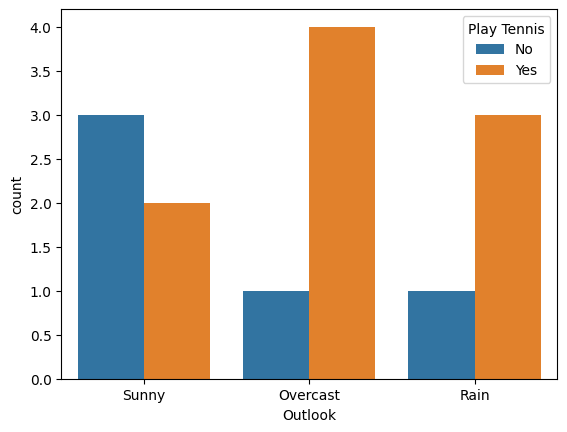

In [60]:
sns.countplot(x='Outlook', data=df, hue='Play Tennis')
plt.show()